# Response and recommendation tags

Sample sizes: $N_m$ models, $N_r$ responses. Rule: titles only in PNG; PDFs (paper) have none.

Inputs: `results/responses_metadata/`, `results/recommendations_metadata/` (see `code/scripts/README.md`).

Plots: `results/plots/tags_*`.

In [1]:
# Setup: make code/libs importable from this notebook, and re-import changed library modules
# automatically (otherwise restart the kernel after editing code/libs)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from utils import analysis_config
from utils import constants as cons
from utils import ios
from responses import tag_stats
from viz import constants as viscons
from viz import tag_plots
from viz.figures import save_figure
from viz.labels import sample_size_label
from viz.captions import print_caption, tags_figure_caption
from viz.style import apply_style

apply_style()   # scientific-paper style for all figures (viz/style.py)

'DejaVu Serif'

In [2]:
# Parameters
CONFIG = PROJECT / 'config' / 'analysis.yaml'           # analysis config: validity.valid_response_tags / valid_rec_tags
VALID_RESPONSE_TAGS = None                               # None = from CONFIG; or a list to try another definition
VALID_REC_TAGS = None                                    # e.g. ['correct', 'title_removed']
TOP_N = cons.TOP_COMBINATIONS_PER_FAMILY
MODELS = None                                            # None = all models
SAVE = True

# Valid tags: the same as the metrics use (config), unless set above. They are late settings: decide them here, then
# write them with  python code/scripts/configure_analysis.py --phase late
validity = analysis_config.load(CONFIG)['validity']
VALID_RESPONSE_TAGS = list(VALID_RESPONSE_TAGS or validity['valid_response_tags'])
VALID_REC_TAGS = list(VALID_REC_TAGS or validity['valid_rec_tags'])
print(f"valid response tags: {VALID_RESPONSE_TAGS}\nvalid recommendation tags: {VALID_REC_TAGS}"
      f"\n(config {CONFIG.name}; late settings reviewed: {analysis_config.late_reviewed(CONFIG)})")

valid response tags: ['correct', 'wrapped', 'python_literal', 'embedded']
valid recommendation tags: ['correct', 'title_removed', 'repetition_removed', 'split']
(config analysis.yaml; late settings reviewed: True)


In [3]:
# Data (only the columns needed)
summary = ios.load_parquet_folder(cons.DEFAULT_RESPONSES_METADATA_DIR,
                                  columns=tag_stats.RESPONSE_KEY + [cons.COL_RESPONSE_TAGS], models=MODELS)
recommendations = ios.load_parquet_folder(cons.DEFAULT_RECOMMENDATIONS_METADATA_DIR,
                                          columns=tag_stats.RESPONSE_KEY + [cons.COL_REC_TAGS], models=MODELS)
print(f"{len(summary):,} responses | {len(recommendations):,} recommendations | {summary[cons.COL_MODEL].nunique()} models")

928,800 responses | 3,869,884 recommendations | 43 models


## 1. Responses

In [4]:
response_categories = tag_stats.CombinationCategories.from_combinations(summary[cons.COL_RESPONSE_TAGS], VALID_RESPONSE_TAGS, TOP_N)
response_palette = tag_plots.TagPalette(response_categories)
n_models, n_responses = summary[cons.COL_MODEL].nunique(), len(summary)

### 1a. Per model

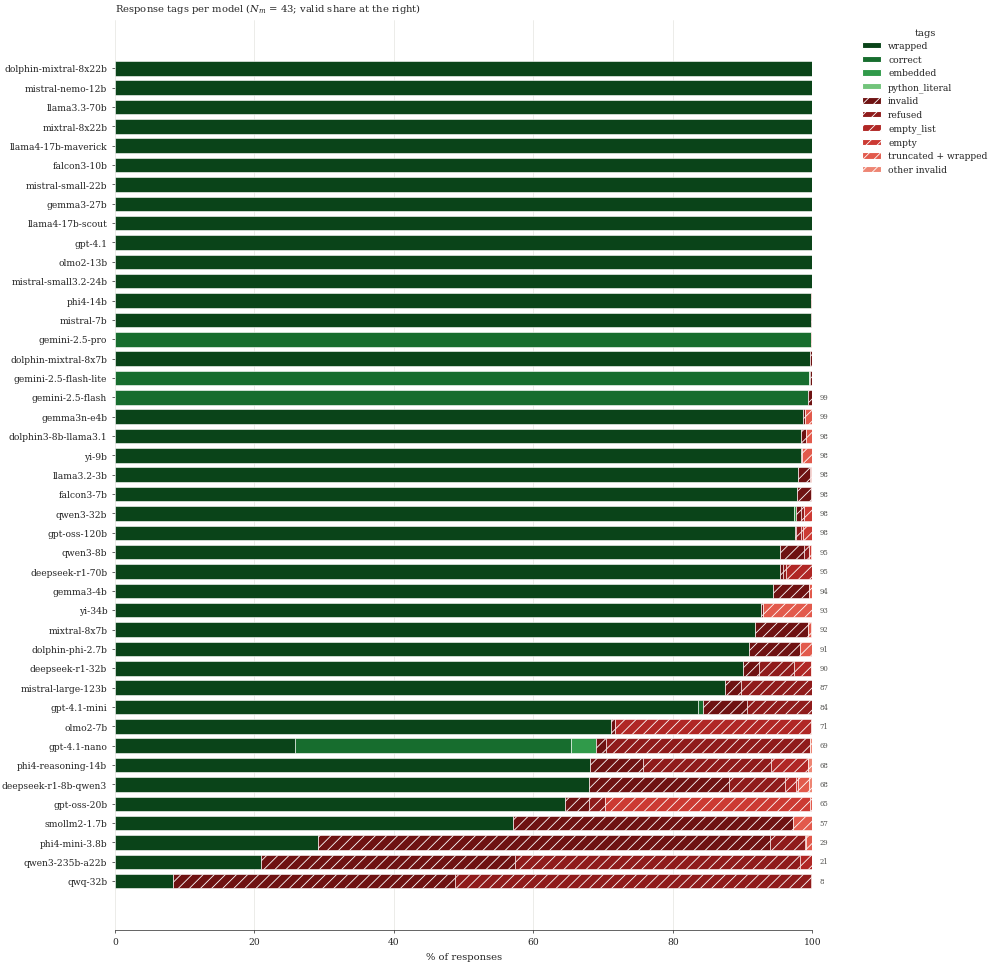

In [5]:
response_shares = tag_stats.shares_by_group(summary, cons.COL_RESPONSE_TAGS, response_categories)
fig = tag_plots.plot_tags_per_model(response_shares, response_palette, value_label='% of responses',
                                    title=f'Response tags per model ({sample_size_label(n_models)}; valid share at the right)')

### 1b. All models (mean of model shares, 95% CI)

,category,mean,ci_low,ci_high,std_models,n_models,n_rows,is_valid,n,pct
0,wrapped,79.510551,69.841747,88.228663,32.346288,43,928800,True,738494,79.510551
1,correct,7.884798,1.785061,16.658788,26.116702,43,928800,True,73234,7.884798
2,embedded,0.091193,0.000754,0.273283,0.536937,43,928800,True,847,0.091193
3,python_literal,0.002584,0.000000,0.007647,0.012009,43,928800,True,24,0.002584
4,invalid,5.992033,2.517751,10.249257,13.724612,43,928800,False,55654,5.992033
5,refused,4.221038,1.580731,7.628828,10.923063,43,928800,False,39205,4.221038
6,empty_list,1.021964,0.144625,2.409429,4.365399,43,928800,False,9492,1.021964
7,empty,0.761628,0.026214,2.230817,4.475196,43,928800,False,7074,0.761628
8,truncated|wrapped,0.454457,0.162772,0.833489,1.196775,43,928800,False,4221,0.454457
9,other invalid,0.059755,0.025829,0.100797,0.128275,43,928800,False,555,0.059755


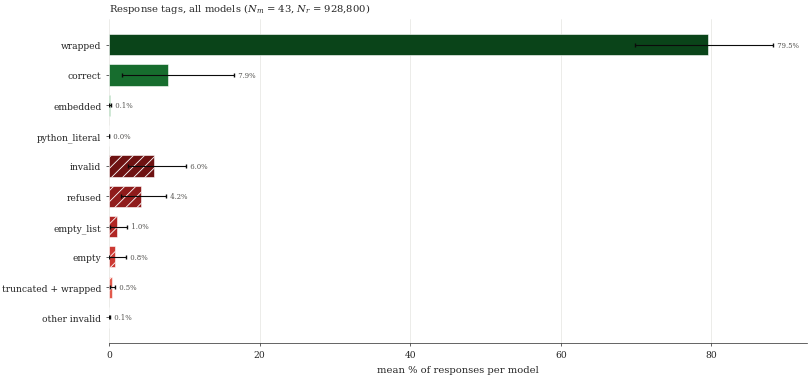

In [6]:
response_stats = tag_stats.model_mean_shares(summary, cons.COL_RESPONSE_TAGS, response_categories)
fig = tag_plots.plot_tags_overall(response_stats, response_palette, value='mean', value_label='mean % of responses per model',
                                  title=f'Response tags, all models ({sample_size_label(n_models, n_responses)})')
response_stats.merge(tag_stats.overall_shares(summary, cons.COL_RESPONSE_TAGS, response_categories)[['category', 'n', 'pct']],
                     on='category')   # pooled counts for reference

### 1c. Paper figure

1a (4/5) and 1b (1/5) in one figure, vertical bars, A4 width. $N_m$ and $N_r$ are annotated inside the
overall panel (no per-model title); titles only in the PNG. Saved as PDF (vector; `viscons.PAPER_FIGURE_FORMATS`).

Output format of the LLM responses. Left, share of each model's responses per tag combination ($N_r$
= 928,800 responses from $N_m$ = 43 models); models are sorted by their share of valid responses,
written above each bar when below 100%. Right, mean of the model-level shares (models weighted
equally); error bars, 95% confidence intervals from a hierarchical bootstrap (1,000 replicates;
models resampled, then prompt configurations within models). A response is valid if all its tags are
among correct, wrap, py_lit, embed (green); all other combinations are red and hatched. Darker
shades denote more frequent combinations; the five most frequent combinations of each group are
shown and the rest are pooled as "other valid" and "other invalid". Tags (+, co-occurring tags):
correct, strict JSON array of recommendations, no other issue; py_lit, not valid JSON but valid
Python literal syntax (e.g. single quotes, True/None, a trailing comma before } or ], an unescaped
control character such as 

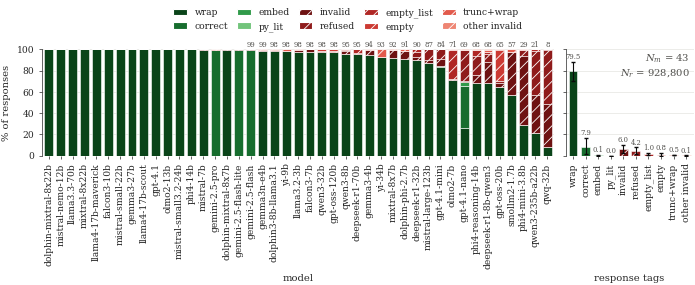

In [7]:
fig = tag_plots.plot_tags_paper_figure(response_shares, response_stats, response_palette, value='mean',
                                       value_label='% of responses', tags_label='response tags',
                                       annotation=sample_size_label(n_models, n_responses, separator='\n'))
if SAVE: save_figure(fig, f'{cons.PREFIX_PLOT_TAGS}_responses_paper', formats=viscons.PAPER_FIGURE_FORMATS)
print_caption(tags_figure_caption('responses', response_categories, VALID_RESPONSE_TAGS,
                                  n_models=n_models, n_responses=n_responses, n_units=n_responses))

## 2. Recommendations

In [8]:
rec_categories = tag_stats.CombinationCategories.from_combinations(recommendations[cons.COL_REC_TAGS], VALID_REC_TAGS, TOP_N)
rec_palette = tag_plots.TagPalette(rec_categories)
rec_n_models = recommendations[cons.COL_MODEL].nunique()
rec_n_responses = len(recommendations[tag_stats.RESPONSE_KEY].drop_duplicates())   # responses with recommendations

### 2a. Per model

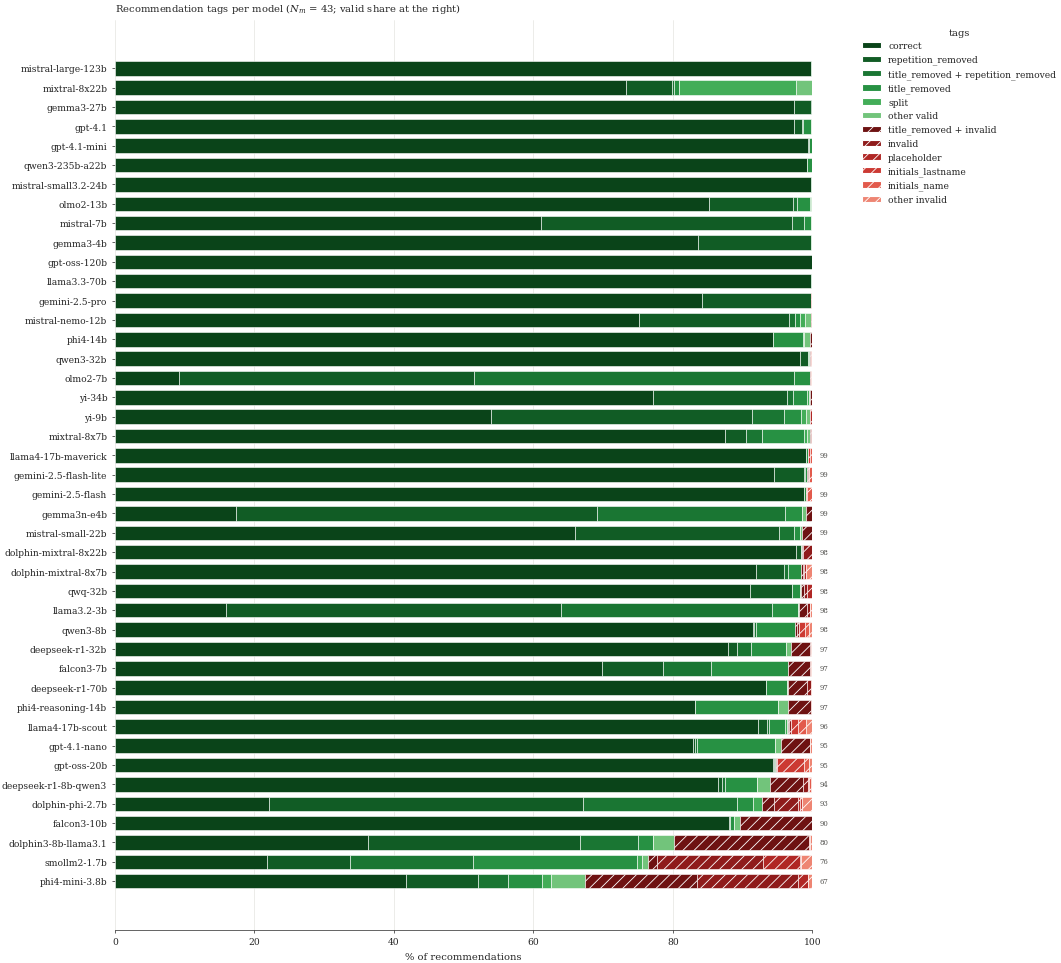

In [9]:
rec_shares = tag_stats.shares_by_group(recommendations, cons.COL_REC_TAGS, rec_categories)
fig = tag_plots.plot_tags_per_model(rec_shares, rec_palette, value_label='% of recommendations',
                                    title=f'Recommendation tags per model ({sample_size_label(rec_n_models)}; valid share at the right)')

### 2b. All models (mean of model shares, 95% CI)

$N_r$ = responses with recommendations.

,category,mean,ci_low,ci_high,std_models,n_models,n_rows,is_valid
0,correct,77.671143,69.537331,85.096325,26.846901,43,3869884,True
1,repetition_removed,10.907148,6.951068,15.614204,15.502958,43,3869884,True
2,title_removed|repetition_removed,4.185596,1.839204,7.271487,9.712106,43,3869884,True
3,title_removed,2.848618,1.721821,4.294134,4.405512,43,3869884,True
4,split,0.547816,0.090750,1.394726,2.533435,43,3869884,True
5,other valid,0.503569,0.266978,0.837000,0.953942,43,3869884,True
6,title_removed|invalid,1.751690,0.759176,2.995474,4.059233,43,3869884,False
7,invalid,0.883392,0.116731,1.981595,3.162081,43,3869884,False
8,placeholder,0.200193,0.031877,0.508878,0.817364,43,3869884,False
9,initials_lastname,0.174858,0.042794,0.400797,0.617288,43,3869884,False


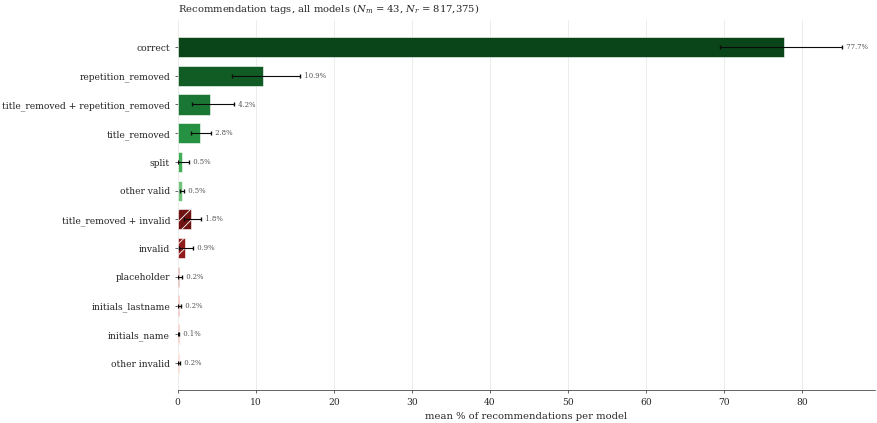

In [10]:
rec_stats = tag_stats.model_mean_shares(recommendations, cons.COL_REC_TAGS, rec_categories)
fig = tag_plots.plot_tags_overall(rec_stats, rec_palette, value='mean', value_label='mean % of recommendations per model',
                                  title=f'Recommendation tags, all models ({sample_size_label(rec_n_models, rec_n_responses)})')
rec_stats

### 2c. Paper figure

2a (4/5) and 2b (1/5) in one figure; models sorted by % valid recommendations (correct + title_removed).
$N_m$ and $N_r$ are annotated inside the overall panel; titles only in the PNG.

Name quality of the recommended scholars. Left, share of each model's recommendations per tag
combination ($N_{rec}$ = 3,869,884 recommendations in the $N_r$ = 817,375 responses that contain
recommendations, from $N_m$ = 43 models); models are sorted by their share of valid recommendations,
written above each bar when below 100%. Right, mean of the model-level shares (models weighted
equally); error bars, 95% confidence intervals from a hierarchical bootstrap (1,000 replicates;
models resampled, then prompt configurations within models). A recommendation is valid if all its
tags are among correct, title_rm, rep_rm, split (green); all other combinations are red and hatched.
Darker shades denote more frequent combinations; the five most frequent combinations of each group
are shown and the rest are pooled as "other valid" and "other invalid". Tags (+, co-occurring tags):
correct, first and last name given as requested; title_rm, academic or honorific title removed (e.g.
Dr., Prof.); rep_

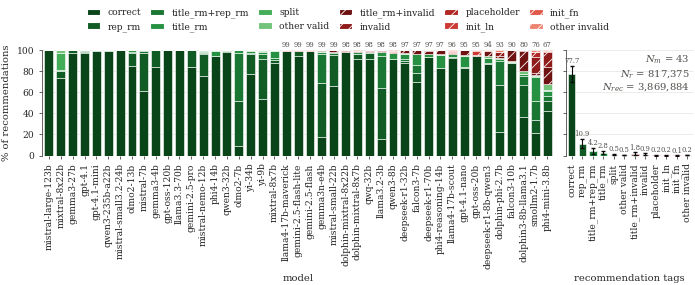

In [11]:
fig = tag_plots.plot_tags_paper_figure(rec_shares, rec_stats, rec_palette, value='mean',
                                       value_label='% of recommendations', tags_label='recommendation tags',
                                       annotation=sample_size_label(rec_n_models, rec_n_responses, len(recommendations),
                                                                    separator='\n'))
if SAVE: save_figure(fig, f'{cons.PREFIX_PLOT_TAGS}_recommendations_paper', formats=viscons.PAPER_FIGURE_FORMATS)
print_caption(tags_figure_caption('recommendations', rec_categories, VALID_REC_TAGS,
                                  n_models=rec_n_models, n_responses=rec_n_responses, n_units=len(recommendations)))